# Exploring Outbreak Dynamics

## Introduction

This notebook explores the dynamics of infectious disease transmission through a hypothetical outbreak of **Slurry-Throat Congestion (STC)**.

STC is an entirely fictional infectious condition characterized by the sensation of a thick, sticky, oatmeal-like substance coating the throat.

**STC is entirely fictional.** Its transmission characteristics, infectious period, recovery dynamics, and responses to public health interventions are hypothetical parameters selected for computational experimentation. No real pathogen, clinical syndrome, or observed outbreak is being modeled.

The simulations use the 2025 Vintage Estimates of the Resident Population for Counties and 2025 TIGER/Line Shapefiles. The original data sources are available from the [U.S. Census Bureau population estimates](https://www.census.gov/data/tables/time-series/demo/popest/2020s-counties-total.html) and [2025 TIGER/Line Shapefiles](https://www.census.gov/geographies/mapping-files/2025/geo/tiger-line-file.html).

Using these datasets, the simulations explore how epidemic dynamics change under different assumptions about transmission, population mixing, geographic connectivity, isolation, quarantine, and intervention timing.

The objective is not to forecast an actual outbreak, but to develop an intuitive and quantitative understanding of infectious disease modeling, progressing from classical susceptible–infectious–removed (SIR) models to geographically structured simulations.

## Data Loading and Setup

We use 2025 U.S. Census county population estimates and TIGER/Line geographic data to define the population and spatial structure of the simulations.

The processed datasets contain county-level population estimates, geographic identifiers, coordinates, and county adjacency relationships for the Contiguous United States (lower 48 states). These were constructed using `dataset_builder.py`.

All simulations use the same underlying population data, beginning with a single nationally aggregated population and progressing toward geographically structured models.

In [11]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp

# Load processed datasets

DATA_DIR = Path("Data_Processed")

counties = pd.read_csv(
    DATA_DIR / "counties.csv",
    dtype={"fips": str, "state_fips": str}
)

# DON'T NEED THIS YET

# edges = pd.read_csv(
#     DATA_DIR / "edges.csv",
#     dtype={"source_fips": str, "target_fips": str}
# )

geography = gpd.read_file(
    DATA_DIR / "county_network.geojson"
)

geography["fips"] = geography["fips"].astype(str).str.zfill(5)

# Validate datasets

assert counties["fips"].is_unique, "Duplicate county FIPS codes"
assert counties["population_2025"].notna().all(), "Missing populations"
assert (counties["population_2025"] > 0).all(), "Invalid populations"

# assert set(edges["source_fips"]).issubset(counties["fips"])
# assert set(edges["target_fips"]).issubset(counties["fips"])
assert set(geography["fips"]) == set(counties["fips"])

# Define total population

N = int(counties["population_2025"].sum())

print(f"Counties: {len(counties):,}")
# print(f"Border connections: {len(edges):,}")
print(f"Population (2025): {N:,}")

Counties: 3,108
Population (2025): 338,921,122


# 1. The Simplest Outbreak: Introducing the SIR Model

Before introducing geographic transmission or public health interventions, we begin with a classical **susceptible–infectious–removed (SIR)** model.

The SIR model divides a population into three compartments:

* **Susceptible ($S$)**: Individuals who have not been infected and remain susceptible to Disease STC.
* **Infectious ($I$)**: Individuals currently infected with STC who can transmit the disease.
* **Removed ($R$)**: Individuals who have recovered or otherwise left the infectious population and can no longer transmit STC.

Individuals transition from susceptible to infectious through transmission, and from infectious to removed through recovery or removal.

For this initial simulation, we make several simplifying assumptions:

1. The population is closed, with no births, deaths, or migration.

2. Individuals mix homogeneously, meaning that every individual has the same opportunity for infectious contact.

3. Transmission and removal rates remain constant throughout the outbreak.

4. Removed individuals cannot become susceptible again.

5. There is no incubation period, so newly infected individuals enter the infectious compartment immediately.

Although these assumptions are unrealistic for most infectious diseases, they provide a useful starting point for understanding how epidemics develop.

## 1.1 Mathematical Formulation

The classical SIR model describes how individuals move between three compartments over time: susceptible ($S$), infectious ($I$), and removed ($R$).

Rather than calculating the number of individuals in each compartment directly, the model first calculates **how quickly each compartment is changing**. These rates of change are described using ordinary differential equations.

### 1.1.1 Model parameters

We begin with the following hypothetical values for STC:

| Symbol | Description | Value |
|---|---|---|
| $N$ | Total population | Sum of 2025 county populations |
| $S_0$ | Initially susceptible | $N-100$ |
| $I_0$ | Initially infectious | 100 people |
| $R_{\mathrm{initial}}$ | Initially removed | 0 people |
| $\beta$ | Effective transmission-rate parameter | 0.30 per day |
| $\gamma$ | Per-capita removal rate | 0.10 per day |
| $t$ | Time | Days |

The population remains constant throughout the simulation:

$$
N=S+I+R
$$

The notation $dS/dt$, $dI/dt$, and $dR/dt$ represents the instantaneous rate of change in each compartment, measured in people per day. A positive value indicates an increasing population, while a negative value indicates a decreasing population. These equations calculate rates of change, not the exact number of people in each compartment on the following day.

### 1.1.2 Susceptible population

$$
\frac{dS}{dt}=-\beta\frac{SI}{N}
$$

The susceptible population decreases as individuals become infected.

The expression $\beta SI/N$ calculates the rate of new infections based on the current susceptible population, infectious population, and transmission parameter. The negative sign indicates that these infections remove individuals from the susceptible compartment.

### 1.1.3 Infectious population

$$
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I
$$

The infectious population changes through two competing processes:

1. **New infections** increase the infectious population.
2. **Removals** decrease the infectious population.

If new infections occur faster than removals, the infectious population grows. If removals occur faster than new infections, the infectious population declines.

### 1.3.4 Removed population

$$
\frac{dR}{dt}=\gamma I
$$

The removed population increases as infectious individuals recover or otherwise leave the infectious compartment.

With $\gamma=0.10$ per day, the model assumes that infectious individuals leave the compartment at a constant per-capita rate of 0.10 per day. Under this model, the average time spent infectious is:

$$
\frac{1}{\gamma}=\frac{1}{0.10}=10\text{ days}
$$

In [12]:
I0 = 100
R0_initial = 0
S0 = N - I0 - R0_initial

# Hypothetical STC transmission parameters

beta = 0.30     # Effective transmission rate (per day)
gamma = 0.10    # Removal rate (per day)
days = 365      # Days to run simulation (one year)

# SIR differential equation definition

def sir_model(t, y, beta, gamma, N):
    # Susceptible, Infected, and Removed counts
    S, I, R = y

    # Instantaneous rate of new infections (people per day)
    new_infections = beta * S * I / N

    # Instantaneous rate of new removals (people per day)

    new_removals = gamma * I

    return [
        # People can only be removed from suceptible
        -new_infections,
        # New infections increase infected and new removals decrease infected
        new_infections - new_removals,
        # People can only be added to removed
        new_removals
    ]

# Solve the model

t = np.arange(days + 1)

solution = solve_ivp(
    sir_model,
    # Loop from 0--366 (365 days / 1 year)
    t_span=(0, days),
    # Initial parameters for day 0
    y0=[S0, I0, R0_initial],
    # Transmission rate, removal rate, total population
    args=(beta, gamma, N),
    t_eval=t,
    rtol=1e-8,
    atol=1e-8
)

if not solution.success:
    raise RuntimeError(solution.message)

results = pd.DataFrame({
    "day": solution.t,
    "S": solution.y[0],
    "I": solution.y[1],
    "R": solution.y[2]
})

## 1.2 Initial Outbreak Simulation

With the model equations defined, we can now simulate the spread of STC through the population.

We begin by introducing 100 infectious individuals into an otherwise susceptible population. Using hypothetical transmission and removal rates, we simulate changes in the three compartments over 365 days (1 year).

The model is implemented using Python's `solve_ivp()` function, which numerically solves the differential equations by evaluating how quickly each compartment changes over time.

The resulting estimates describe the number of susceptible, infectious, and removed individuals at each simulated day.

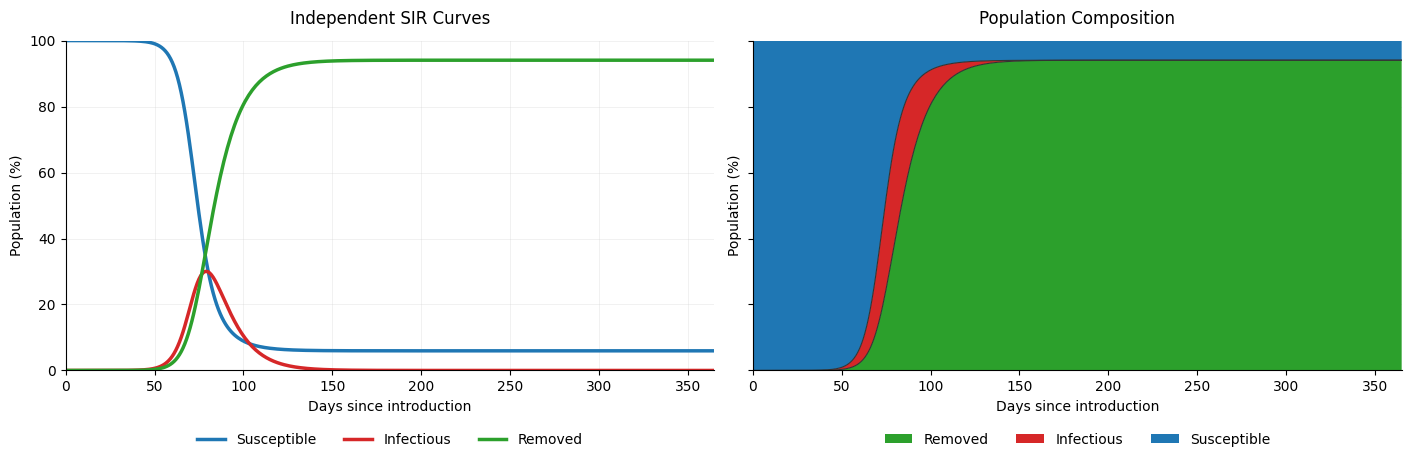

In [13]:
from notebook_helpers import (
    sir_curves_plot,
    sir_stacked_plot,
)
from notebook_helpers import (
    sir_curves_plot,
    sir_stacked_plot,
)
# Plots

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

# Independent SIR curves

sir_curves_plot(
    results,
    N,
    ax=axes[0],
    title="Independent SIR Curves",
)

# Population composite SIR cur

sir_stacked_plot(
    results,
    N,
    ax=axes[1],
    title="Population Composition",
)

plt.show()

### 1.2.1 Interpretation: Initial Outbreak

The simulation illustrates how the population transitions between susceptible, infectious, and removed compartments over the course of an STC outbreak.

Initially, nearly the entire population is susceptible, with only 100 infectious individuals introduced into the population. As these individuals transmit STC to others, the infectious population gradually increases before entering a period of rapid growth.

As the outbreak progresses, the susceptible population declines while the removed population increases. The infectious population eventually reaches a maximum before declining toward zero, even though some individuals remain susceptible.

The two visualizations illustrate these dynamics differently. The independent curves show how each compartment changes over time, while the stacked plot illustrates how the population is distributed among the three compartments. At every point in the simulation, the three compartments collectively represent 100% of the population.

## 1.3 Measuring an Epidemic: Incidence, Prevalence, and Attack Rate

The different compartments ($S$, $I$, $R$), can be used to calculate epidemiologic measures that help describe and compare outbreaks for different epidemics. This will help us measure how epidemics change amongst one-another in the upcoming sections.

The three basic comparative measures are **incidence, prevalence, and cumulative attack rate**.

### 1.3.1 Incidence

Incidence describes the occurrence of new infections within a population over a specified period.

In our SIR model, susceptible individuals leave the susceptible compartment when they become infected. This allows us to calculate the number of new infections occurring between two observations by measuring the decrease in the susceptible population.

For consecutive daily observations:

$$
\text{New infections during day }t=S(t-1)-S(t)
$$

We can express this as a daily infection count per 100,000 population:

$$
\text{Daily infections per 100,000}=
\frac{S(t-1) - S(t)}{N} \times 100,000
$$

This provides a population-standardized measure of new infections during each day.

### 1.3.2 Prevalence

Prevalence describes the proportion of a population experiencing a condition at a particular point in time.

In our model, we can calculate the proportion of individuals currently infectious:

$$
\text{Infectious prevalence (\%)}=\frac{I(t)}{N} \times 100
$$

Unlike incidence, which describes new infections, prevalence describes the number of individuals who are infectious at a particular moment.

A population may experience relatively few new infections while still having a substantial infectious population, particularly when individuals remain infectious for longer periods. Prevalence is typically higher than incidence for chronic diseases, while incidence is typically higher than prevalence for acute diseases.

### 1.3.3 Cumulative Attack Rate

The cumulative attack rate is a measure of the proportion of an initially susceptible population that becomes infected during a defined outbreak period.

For our closed SIR model:

$$
\text{Cumulative attack rate (\%)}=
\frac{S(0) - S(t)}{S(0)} \times 100
$$

This measure describes the proportion of individuals who were susceptible at the beginning of the simulation and then became infected.

Unlike infectious prevalence, the cumulative attack rate does not decrease when individuals enter the removed compartment.

### 1.3.4 Comparing the Measures

Although these measures describe the same outbreak, they answer different questions:

| Measure | Epidemiological question |
|---|---|
| Daily incidence | How many new infections are occurring? |
| Infectious prevalence | How many individuals are currently infectious? |
| Cumulative attack rate | What proportion of the initially susceptible population has been infected? |

We'll start by measuring these for the initial SIR model before moving to the different transmission rate (\beta) scenarios.

,day,S,I,R,daily_infections,incidence_per_100k,prevalence_pct,attack_rate_pct
0,0,3.389210e+08,100.000000,0.000000,NaN,NaN,0.000030,0.000000
1,1,3.389210e+08,122.140263,11.070137,33.210401,0.009799,0.000036,0.000010
2,2,3.389209e+08,149.182434,24.591232,40.563266,0.011968,0.000044,0.000022
3,3,3.389209e+08,182.211805,41.105932,49.544070,0.014618,0.000054,0.000036
4,4,3.389208e+08,222.553951,61.277028,60.513242,0.017855,0.000066,0.000054


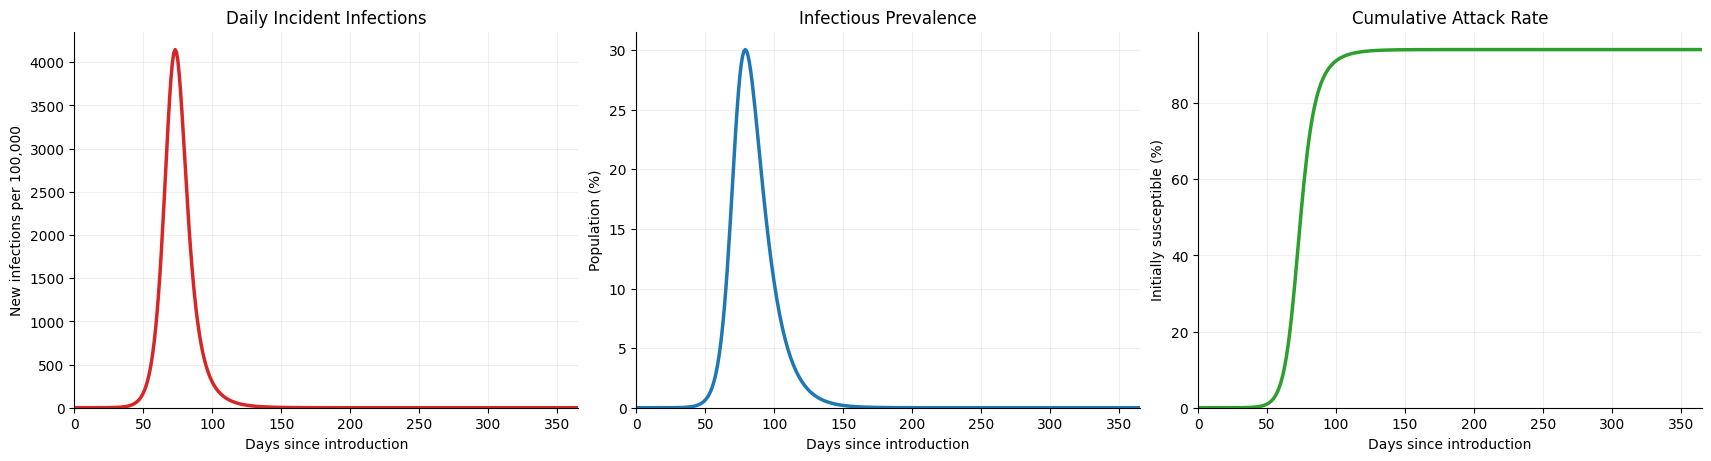

In [14]:
from notebook_helpers import (
    epidemiological_measures_plot
)

# Calculate epidemiological measures for the baseline outbreak
epi_results = results.copy()

# New infections during each preceding one-day interval
epi_results["daily_infections"] = (
    -epi_results["S"].diff()
)

# Daily infections per 100,000 total population
epi_results["incidence_per_100k"] = (
    epi_results["daily_infections"] / N * 100_000
)

# Proportion of population currently infectious
epi_results["prevalence_pct"] = (
    epi_results["I"] / N * 100
)

# Proportion of initially susceptible individuals infected
epi_results["attack_rate_pct"] = (
    (S0 - epi_results["S"]) / S0 * 100
)

display(epi_results.head())

fig, axes = epidemiological_measures_plot(epi_results)

### 1.3.5 Interpretation: Epidemiological Measure

The three metrics above illustrate different aspects of a disease outbreak:

1. **Daily Incident Infections (Incidence per 100k):**

   * Measures the flow of new cases per day.

   * Daily incidence peaks just before infectious prevalence does. This occurs because the daily rate of new infections slows down first, followed by the total pool of infectious people, leading to the greatest instantaneous value for the cumulative attack rate.

   * This is the primary metric for tracking how fast a disease is infecting new people.

2. **Infectious Prevalence (Active Disease Pool):**

   * Measures the number of individuals capable of transmitting STC at any single point in time.

   * Includes both new and active cases.

3. **Cumulative Attack Rate (Historical Exposure):**

   * Measures the percentage of initially susceptible individuals who have ever contracted STC ($[S(0) - S(t)] / S(0)$).
   
   * This value doesn't reach 100% of the population. That's because an epidemic ends when the depletion of susceptible hosts deprives the pathogen of the transmission density needed to sustain positive growth ($R_t < 1$).

## 1.4 Exploring the Transmission Rate

Our initial simulation assumed a transmission-rate parameter of $\beta=0.30$ per day. However, this value was selected hypothetically, and different transmission rates may produce substantially different outbreak trajectories.

The transmission parameter ($\beta$) determines how quickly infections occur for a given number of susceptible and infectious individuals. Increasing $\beta$ increases the instantaneous rate of new infections, while decreasing it reduces that rate.

To investigate how transmission influences outbreak dynamics and the epidemiological measures we established in Section 1.3 (incidence, prevalence, and attack rate), we will simulate three scenarios:

| Scenario | Transmission rate ($\beta$) |
|---|---|
| Lower transmission | 0.15 |
| Baseline transmission | 0.30 |
| Higher transmission | 0.45 |

All other parameters and initial conditions will remain unchanged:

- Initial infectious population: 100 individuals
- Initial removed population: 0 individuals
- Removal rate ($\gamma$): 0.10 per day
- Population: 2025 contiguous U.S. population ($N$)
- Simulation duration: 365 days (1 year)

By changing only $\beta$, we can isolate its influence on the speed, scale, and burden of the simulated outbreak.

In [15]:
# Define transmission scenarios
transmission_scenarios = {
    "Lower transmission": 0.15,
    "Baseline transmission": 0.30,
    "Higher transmission": 0.45,
}

# Store each simulation's results and calculated metrics
transmission_results = {}

for scenario, beta_value in transmission_scenarios.items():
    # Solve SIR model
    solution = solve_ivp(
        sir_model,
        t_span=(0, days),
        y0=[S0, I0, R0_initial],
        args=(beta_value, gamma, N),
        t_eval=np.arange(days + 1),
        rtol=1e-8,
        atol=1e-8,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    df = pd.DataFrame({
        "day": solution.t,
        "S": solution.y[0],
        "I": solution.y[1],
        "R": solution.y[2],
    })

    # Compute epidemiological measures
    df["daily_infections"] = -df["S"].diff()
    df["incidence_per_100k"] = (df["daily_infections"] / N) * 100_000
    df["prevalence_pct"] = (df["I"] / N) * 100
    df["attack_rate_pct"] = ((S0 - df["S"]) / S0) * 100

    transmission_results[scenario] = df

### 1.4.1 Plotting $\beta$ Scenarios

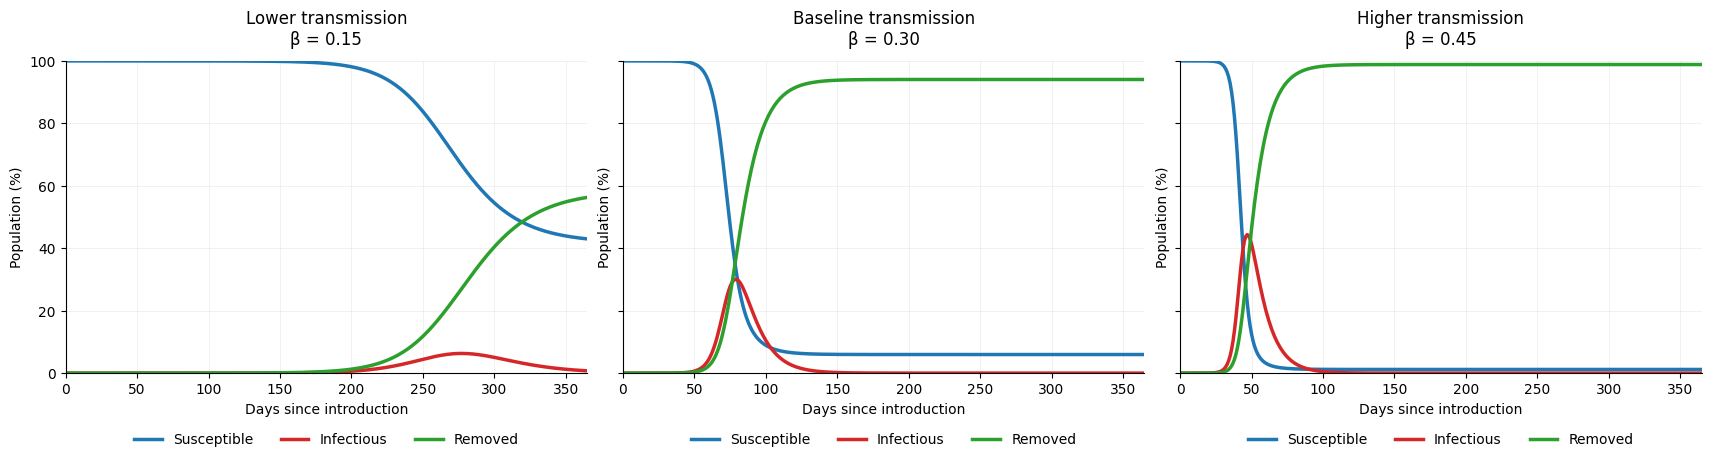

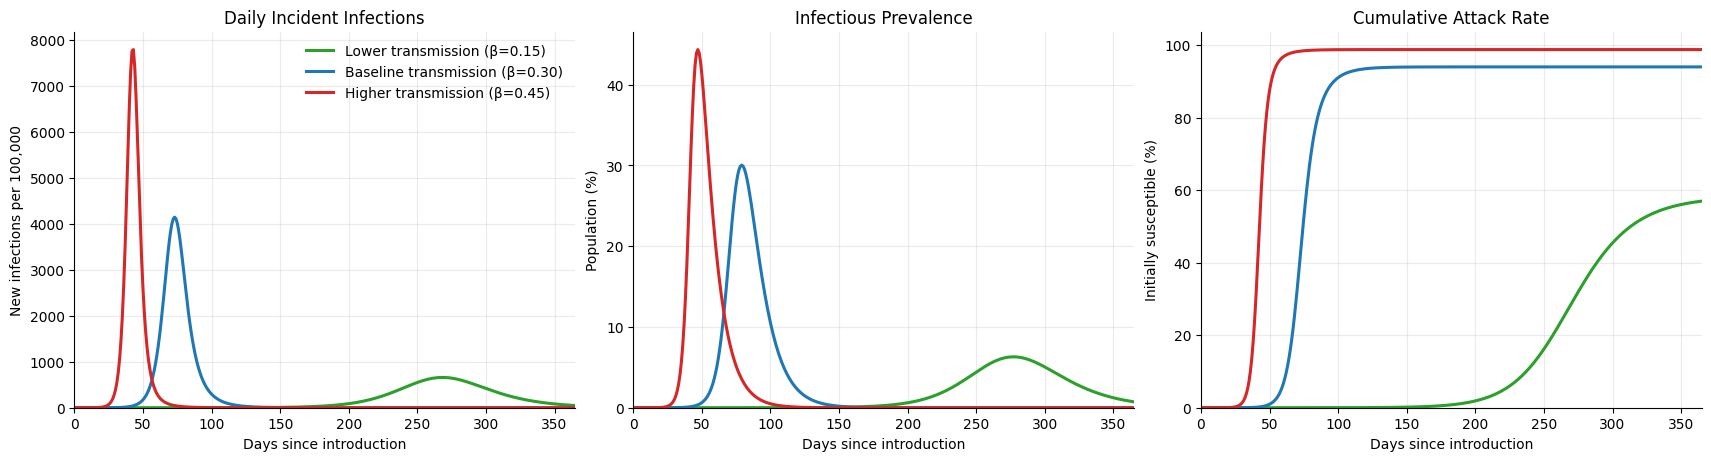

,Scenario,β,Peak Incidence Day,Peak Daily Incidence (per 100k),Peak Prevalence Day,Peak Prevalence (%),Final Attack Rate Day 365 (%)
0,Lower transmission,0.15,268,659.12,277,6.30,57.01
1,Baseline transmission,0.30,73,4146.09,79,30.05,94.05
2,Higher transmission,0.45,43,7792.34,47,44.35,98.83


In [16]:
# 1. Plot independent SIR curves for each scenario
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, (scenario, beta_value) in zip(axes, transmission_scenarios.items()):
    sir_curves_plot(
        transmission_results[scenario],
        N,
        ax=ax,
        title=f"{scenario}\nβ = {beta_value:.2f}",
    )

plt.show()

# 2. Comparative curves for the three epidemiological measures
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True, constrained_layout=True)

colors = {
    "Lower transmission": "#2CA02C",
    "Baseline transmission": "#1F77B4",
    "Higher transmission": "#D62728",
}

measures = [
    ("incidence_per_100k", "Daily Incident Infections", "New infections per 100,000"),
    ("prevalence_pct", "Infectious Prevalence", "Population (%)"),
    ("attack_rate_pct", "Cumulative Attack Rate", "Initially susceptible (%)"),
]

for ax, (col, title, ylabel) in zip(axes, measures):
    for scenario, df in transmission_results.items():
        ax.plot(
            df["day"],
            df[col],
            color=colors[scenario],
            linewidth=2.2,
            label=f"{scenario} (β={transmission_scenarios[scenario]:.2f})",
        )
    ax.set(title=title, xlabel="Days since introduction", ylabel=ylabel)
    ax.set_xlim(0, days)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].legend(frameon=False, loc="upper right")
plt.show()

# 3. Comprehensive Summary Statistics Table
summary = []

for scenario, df in transmission_results.items():
    peak_prev_idx = df["I"].idxmax()
    # Daily incidence starts on day 1 (index 1) due to diff()
    peak_inc_idx = df["incidence_per_100k"].idxmax()

    summary.append({
        "Scenario": scenario,
        "β": transmission_scenarios[scenario],
        "Peak Incidence Day": df.loc[peak_inc_idx, "day"],
        "Peak Daily Incidence (per 100k)": df["incidence_per_100k"].max(),
        "Peak Prevalence Day": df.loc[peak_prev_idx, "day"],
        "Peak Prevalence (%)": df["prevalence_pct"].max(),
        "Final Attack Rate Day 365 (%)": df["attack_rate_pct"].iloc[-1],
    })

transmission_summary = pd.DataFrame(summary)
display(transmission_summary.round(2))

### 1.4.2 Interpretation: Transmission Rate Scenarios

Comparing the three scenarios across our epidemiological measures highlights how $\beta$ alters the timing, peak intensity, and final scale of an outbreak over a one-year period:

1. **Incidence Leads Prevalence in Timing:**

   * In both the baseline and higher-transmission runs, **peak daily incidence arrives several days before peak prevalence** (Day 43 vs. Day 47 for $\beta=0.45$; Day 73 vs. Day 79 for $\beta=0.30$).

   * This confirms the relationship established in Section 1.3: the daily influx of new infections slows down before the total pool of active cases begins to contract.

2. **Non-Linear Escalation of Daily Burden:**

   * Increasing $\beta$ by 50% from baseline ($0.30 \rightarrow 0.45$) does not merely scale the outbreak linearly—it drastically compresses the timeline. Peak prevalence jumps from 30.05% to 44.35%, and the peak daily infection rate surges from ~4,145 to ~7,790 per 100,000 people.

   * Higher transmission rates concentrate demand on healthcare systems into a narrow, overwhelming surge, whereas lower transmission rates distribute infections over a broader window with a far lower daily burden.

3. **Cumulative Attack Rate Disparities:**

   * By Day 365, cumulative attack rates plateau near 94% for baseline and 98% for higher transmission. In both cases, the outbreak terminates naturally before reaching 100% because the susceptible pool is depleted below the threshold required to sustain positive growth ($R_t < 1$).
   
   * By extending the simulation to a full year, the lower-transmission scenario ($\beta=0.15$) also completes its trajectory: daily incidence peaks on Day 268, prevalence peaks on Day 277, and the cumulative attack rate plateaus at roughly 57%. Because its transmission potential is lower, it depletes the fuel needed for growth at a much lower threshold of total population exposure.

These patterns demonstrate how lowering the transmission rate flattens the curve and reduces cumulative illness. However, $\beta$ represents only half of the transmission equation. To understand what truly governs epidemic thresholds, we must also examine the removal rate ($\gamma$) and the duration of infectiousness.

## 1.5 Exploring the Removal Rate ($\gamma$) and Infectious Duration

In Section 1.4, we examined how the effective transmission rate ($\beta$) shapes the outbreak while holding the removal rate fixed at $\gamma = 0.10$ per day. However, epidemic spread depends not only on how readily transmission occurs upon contact, but also on how long individuals remain in the infectious compartment.

The parameter $\gamma$ represents the per-capita rate at which infectious individuals recover or are otherwise removed. Under the constant-rate assumption of the classical SIR model, the average duration of infectiousness ($\tau$) is the reciprocal of the removal rate:

$$\tau = \frac{1}{\gamma}$$

To explore how the duration of illness affects outbreak timing, healthcare burden, and cumulative spread, we hold the transmission rate constant at the baseline value ($\beta = 0.30$) and compare three recovery scenarios:

| Scenario | Removal Rate ($\gamma$) | Mean Infectious Period ($\tau = 1/\gamma$) |
|---|---|---|
| Rapid recovery | 0.20 per day | 5 days |
| Baseline recovery | 0.10 per day | 10 days |
| Prolonged recovery | 0.05 per day | 20 days |

All other parameters and initial conditions remain identical to earlier simulations:

- Initial infectious population: 100 individuals
- Initial removed population: 0 individuals
- Effective transmission rate ($\beta$): 0.30 per day
- Population: 2025 contiguous U.S. population ($N$)
- Simulation duration: 365 days

By isolating $\gamma$, we can observe how the infectious period directly impacts daily incidence, active prevalence, and the cumulative attack rate.

In [20]:
# Define removal rate scenarios (beta fixed at baseline 0.30)
gamma_scenarios = {
    "Rapid recovery (5 days)": 0.20,
    "Baseline recovery (10 days)": 0.10,
    "Prolonged recovery (20 days)": 0.05,
}

# Extend time horizon slightly to allow slower dynamics to resolve
t_eval_gamma = np.arange(days + 1)

# Store each simulation's results and calculated metrics
gamma_results = {}

for scenario, gamma_value in gamma_scenarios.items():
    solution = solve_ivp(
        sir_model,
        t_span=(0, days),
        y0=[S0, I0, R0_initial],
        args=(beta, gamma_value, N),
        t_eval=t_eval_gamma,
        rtol=1e-8,
        atol=1e-8,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    df = pd.DataFrame({
        "day": solution.t,
        "S": solution.y[0],
        "I": solution.y[1],
        "R": solution.y[2],
    })

    # Compute epidemiological measures
    df["daily_infections"] = -df["S"].diff()
    df["incidence_per_100k"] = (df["daily_infections"] / N) * 100_000
    df["prevalence_pct"] = (df["I"] / N) * 100
    df["attack_rate_pct"] = ((S0 - df["S"]) / S0) * 100

    gamma_results[scenario] = df

### 1.5.1 Plotting $\gamma$ Scenarios

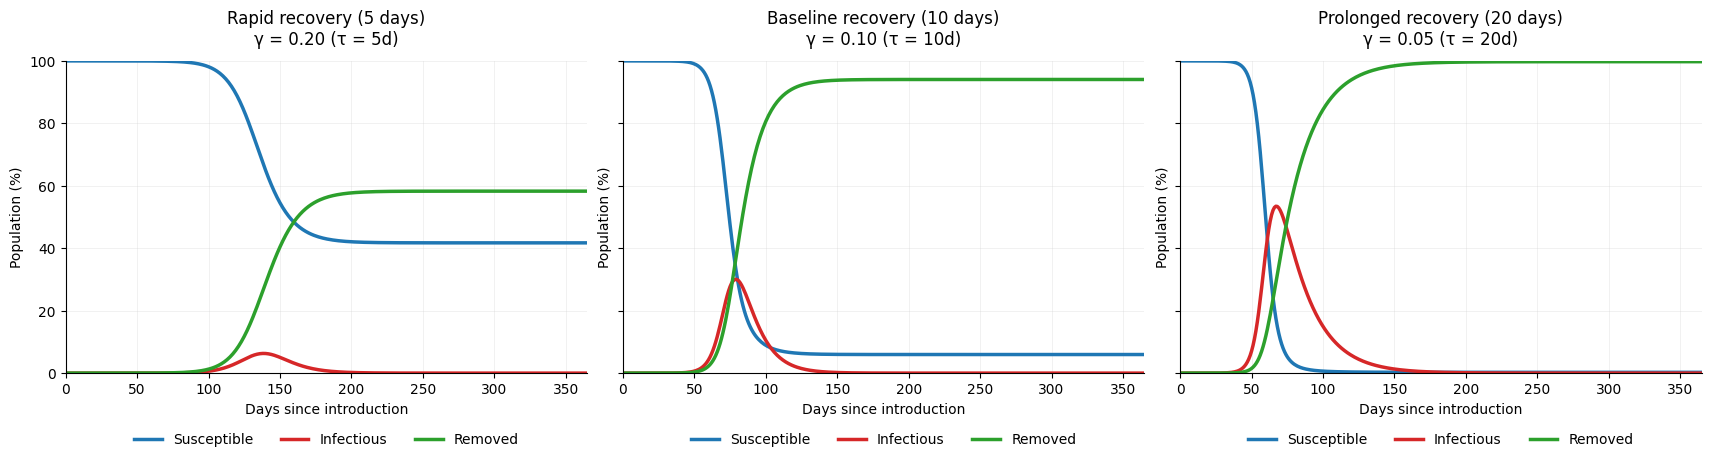

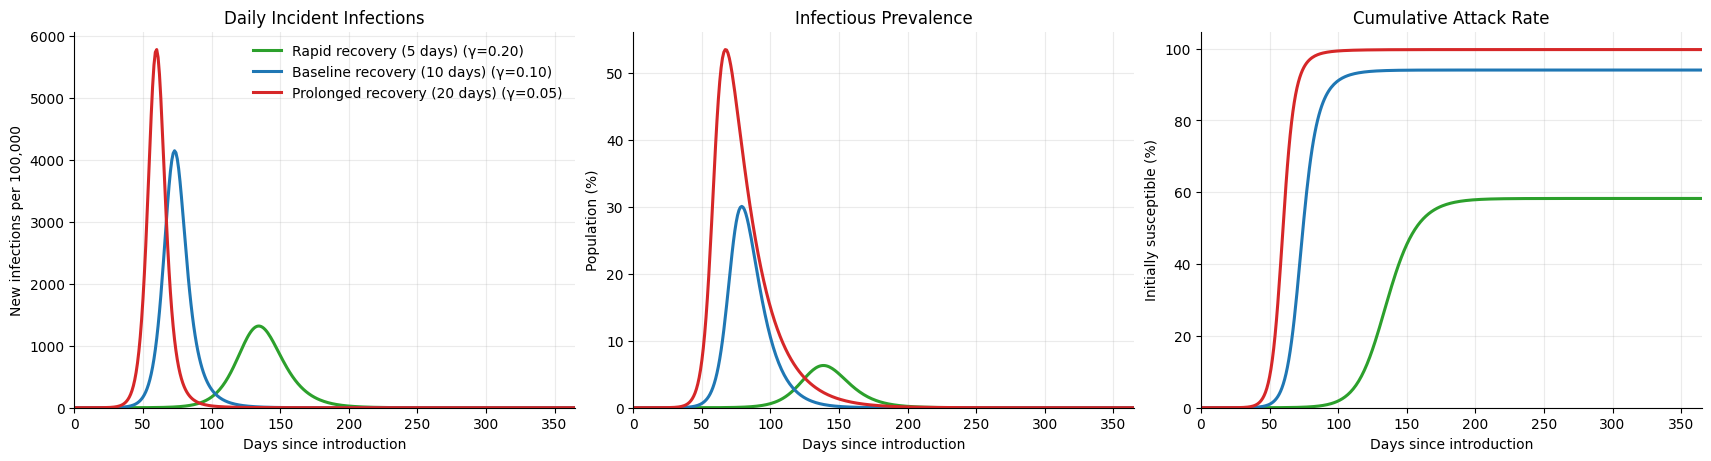

,Scenario,γ,Mean Duration (days),Peak Incidence Day,Peak Daily Incidence (per 100k),Peak Prevalence Day,Peak Prevalence (%),Final Attack Rate (%)
0,Rapid recovery (5 days),0.20,5.0,134,1317.66,139,6.30,58.28
1,Baseline recovery (10 days),0.10,10.0,73,4146.09,79,30.05,94.05
2,Prolonged recovery (20 days),0.05,20.0,60,5778.35,67,53.45,99.75


In [21]:
# 1. Plot independent SIR curves for each scenario
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, (scenario, gamma_value) in zip(axes, gamma_scenarios.items()):
    sir_curves_plot(
        gamma_results[scenario],
        N,
        ax=ax,
        title=f"{scenario}\nγ = {gamma_value:.2f} (τ = {int(1/gamma_value)}d)",
    )

plt.show()

# 2. Comparative curves for the three epidemiological measures
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True, constrained_layout=True)

colors_gamma = {
    "Rapid recovery (5 days)": "#2CA02C",
    "Baseline recovery (10 days)": "#1F77B4",
    "Prolonged recovery (20 days)": "#D62728",
}

measures = [
    ("incidence_per_100k", "Daily Incident Infections", "New infections per 100,000"),
    ("prevalence_pct", "Infectious Prevalence", "Population (%)"),
    ("attack_rate_pct", "Cumulative Attack Rate", "Initially susceptible (%)"),
]

for ax, (col, title, ylabel) in zip(axes, measures):
    for scenario, df in gamma_results.items():
        ax.plot(
            df["day"],
            df[col],
            color=colors_gamma[scenario],
            linewidth=2.2,
            label=f"{scenario} (γ={gamma_scenarios[scenario]:.2f})",
        )
    ax.set(title=title, xlabel="Days since introduction", ylabel=ylabel)
    ax.set_xlim(0, days)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].legend(frameon=False, loc="upper right")
plt.show()

# 3. Comprehensive Summary Statistics Table
summary_gamma = []

for scenario, df in gamma_results.items():
    peak_prev_idx = df["I"].idxmax()
    peak_inc_idx = df["incidence_per_100k"].idxmax()

    summary_gamma.append({
        "Scenario": scenario,
        "γ": gamma_scenarios[scenario],
        "Mean Duration (days)": 1 / gamma_scenarios[scenario],
        "Peak Incidence Day": df.loc[peak_inc_idx, "day"],
        "Peak Daily Incidence (per 100k)": df["incidence_per_100k"].max(),
        "Peak Prevalence Day": df.loc[peak_prev_idx, "day"],
        "Peak Prevalence (%)": df["prevalence_pct"].max(),
        "Final Attack Rate (%)": df["attack_rate_pct"].iloc[-1],
    })

gamma_summary = pd.DataFrame(summary_gamma)
display(gamma_summary.round(2))

### 1.5.2 Interpretation: Removal Rate Scenarios

Comparing the removal rate ($\gamma$) scenarios shows that the duration of illness is just as influential as transmission probability in dictating the timing, burden, and final reach of an epidemic:

1. **Incidence Consistently Leads Prevalence:**

    * Across all three scenarios, peak daily incidence arrives several days before peak prevalence (Day 60 vs. Day 67 for $\tau = 20\text{d}$; Day 73 vs. Day 79 for baseline $\tau = 10\text{d}$; Day 134 vs. Day 139 for $\tau = 5\text{d}$).

    * This reinforces the fundamental relationship that the rate of new infections slows down before the total pool of actively infectious individuals begins to shrink.

2. **Slower Recovery Drives Active Case Accumulation:**

    * Extending the infectious period gives each sick individual a longer window to spread the disease. In the prolonged recovery scenario ($\tau = 20\text{d}$), peak prevalence surges to 53.45%, meaning more than half the population is simultaneously sick around Day 67.

    * While peak daily incidence rises by roughly 39% between baseline and prolonged recovery (~4,146 to ~5,778 per 100k), peak prevalence nearly doubles (30.05% to 53.45%). Slower recovery causes active cases (prevalence) to stack up much faster than individuals can exit the infectious pool.

3. **Rapid Recovery Flattens the Outbreak and Lowers Total Exposure:**

    * Halving the duration of illness to 5 days ($\gamma = 0.20$) significantly suppresses the epidemic. Peak prevalence drops sharply to just 6.30%, and peak daily incidence falls to ~1,318 per 100k, delayed until Day 134.

    * By Day 365, the cumulative attack rate plateaus at 58.28% for rapid recovery, compared to 94.05% for baseline and 99.75% for prolonged recovery.

    * Notice that this 58.28% attack rate is practically identical to the ~58% plateau observed in the lower-transmission scenario ($\beta = 0.15, \gamma = 0.10$).
    
This equivalence reveals a core principle of compartmental modeling: changing the transmission rate ($\beta$) and changing the duration of illness ($1/\gamma$) produce mathematically comparable effects on the final size of an epidemic. What truly governs the outbreak threshold is the ratio between the two: the Basic Reproduction Number ($R_0 = \beta / \gamma$).

## 1.6 Tracking $R_0$, Effective $R_t$, and the Epidemic Threshold

In the preceding two sections, we observed halving the daily transmission rate ($\beta = 0.15, \gamma = 0.10$) and halving the duration of infection ($\beta = 0.30, \gamma = 0.20$) both led to nearly identical final attack rates (~58%).

This occurs because epidemic growth is not governed by $\beta$ or $\gamma$ in isolation, but by their ratio: the **Basic Reproduction Number ($R_0$)**:

$$R_0 = \frac{\beta}{\gamma}$$

$R_0$ represents the average number of secondary infections caused by a single infectious individual introduced into an entirely susceptible population ($S \approx N$).

| Scenario | $\beta$ | $\gamma$ | Mean Duration ($\tau$) | $R_0 = \beta / \gamma$ | Final Attack Rate |
|---|---|---|---|---|---|
| Lower Transmission | 0.15 | 0.10 | 10 days | **1.5** | ~58% |
| Rapid Recovery | 0.30 | 0.20 | 5 days | **1.5** | ~58% |
| Baseline | 0.30 | 0.10 | 10 days | **3.0** | ~94% |
| Higher Transmission | 0.45 | 0.10 | 10 days | **4.5** | ~99% |
| Prolonged Recovery | 0.30 | 0.05 | 20 days | **6.0** | >99% |

### 1.6.1 The Real-Time Gauge: Effective Reproduction Number ($R_t$)

As an outbreak progresses and susceptible individuals get infected and recover, the pool of available hosts shrinks. The average number of secondary cases per infectious person declines in real time according to the **Effective Reproduction Number ($R_t$)**:

$$R_t = R_0 \cdot \frac{S(t)}{N} = \frac{\beta S(t)}{\gamma N}$$

The instantaneous growth rate of the infectious population ($\frac{dI}{dt}$) depends directly on $R_t$:

$$\frac{dI}{dt} = \beta \frac{S(t) I(t)}{N} - \gamma I(t) = \gamma \left( R_t - 1 \right) I(t)$$

This equation establishes the **Epidemic Threshold Theorem**:
* If **$R_t > 1$**: $\frac{dI}{dt} > 0$. Each sick person infects more than one new host; the outbreak accelerates.
* If **$R_t = 1$**: $\frac{dI}{dt} = 0$. The replacement rate is balanced; active infections reach their **peak**.
* If **$R_t < 1$**: $\frac{dI}{dt} < 0$. Transmissions fail to replace recoveries; the epidemic decays.

The point where $R_t$ drops to 1.0 defines the **herd immunity threshold** ($S_{\text{threshold}} = N / R_0$).

### 1.6.2 Baseline Outbreak ($I(t)$ vs. $R_t$)

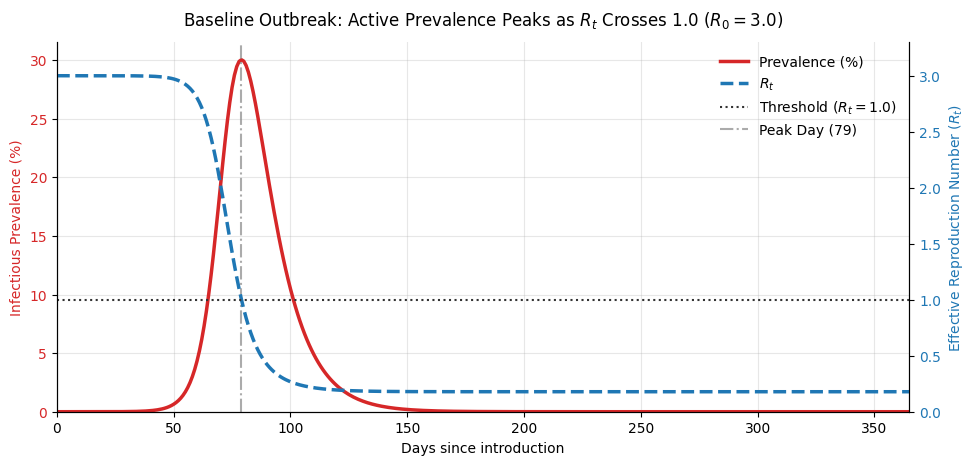

Basic Reproduction Number (R0): 3.00
Day Rt drops to 1.0: Day 79 (Rt = 1.0027)
Day Prevalence Peaks: Day 79 (Prevalence = 30.05%)
Susceptible Fraction at Peak (S/N): 0.3342 (Theoretical 1/R0 = 0.3333)


In [27]:
# Compute R0 and daily Rt for the baseline model across 365 days
t_eval_full = np.arange(days + 1)

# Re-run baseline to guarantee 365-day array consistency
sol_baseline = solve_ivp(
    sir_model,
    t_span=(0, days),
    y0=[S0, I0, R0_initial],
    args=(beta, gamma, N),
    t_eval=t_eval_full,
    rtol=1e-8,
    atol=1e-8,
)

baseline_365 = pd.DataFrame({
    "day": sol_baseline.t,
    "S": sol_baseline.y[0],
    "I": sol_baseline.y[1],
    "R": sol_baseline.y[2],
})

# Calculate R0, Rt, and metrics
R0_base = beta / gamma
baseline_365["Rt"] = R0_base * (baseline_365["S"] / N)
baseline_365["prevalence_pct"] = (baseline_365["I"] / N) * 100
baseline_365["daily_infections"] = -baseline_365["S"].diff()
baseline_365["incidence_per_100k"] = (baseline_365["daily_infections"] / N) * 100_000

# Locate critical inflection points
peak_prev_idx = baseline_365["prevalence_pct"].idxmax()
peak_prev_day = baseline_365.loc[peak_prev_idx, "day"]

# Day where Rt is closest to 1.0
rt_cross_idx = (baseline_365["Rt"] - 1.0).abs().idxmin()
rt_cross_day = baseline_365.loc[rt_cross_idx, "day"]

# Plot: Prevalence vs Rt on dual axis
fig, ax1 = plt.subplots(figsize=(11, 4.8))

color_prev = "#D62728"
color_rt = "#1F77B4"

# Left Axis: Active Prevalence
ax1.set_xlabel("Days since introduction")
ax1.set_ylabel("Infectious Prevalence (%)", color=color_prev)
line1 = ax1.plot(
    baseline_365["day"],
    baseline_365["prevalence_pct"],
    color=color_prev,
    linewidth=2.5,
    label="Prevalence (%)",
)
ax1.tick_params(axis="y", labelcolor=color_prev)
ax1.set_xlim(0, days)
ax1.set_ylim(bottom=0)

# Right Axis: Rt
ax2 = ax1.twinx()
ax2.set_ylabel("Effective Reproduction Number ($R_t$)", color=color_rt)
line2 = ax2.plot(
    baseline_365["day"],
    baseline_365["Rt"],
    color=color_rt,
    linewidth=2.5,
    linestyle="--",
    label="$R_t$",
)
ax2.tick_params(axis="y", labelcolor=color_rt)
ax2.set_ylim(0, R0_base + 0.3)

# Threshold lines
line_thresh = ax2.axhline(1.0, color="#333333", linestyle=":", linewidth=1.5, label="Threshold ($R_t = 1.0$)")
line_peak = ax1.axvline(peak_prev_day, color="#888888", linestyle="-.", alpha=0.7, label=f"Peak Day ({int(peak_prev_day)})")

ax1.set_title(f"Baseline Outbreak: Active Prevalence Peaks as $R_t$ Crosses 1.0 ($R_0 = {R0_base:.1f}$)", pad=12)
ax1.grid(True, alpha=0.3)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# Combined clean legend
lines = line1 + line2 + [line_thresh, line_peak]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right", frameon=False)

plt.show()

# Verification Printout
susceptible_at_peak = baseline_365.loc[peak_prev_idx, "S"]
print(f"Basic Reproduction Number (R0): {R0_base:.2f}")
print(f"Day Rt drops to 1.0: Day {rt_cross_day:.0f} (Rt = {baseline_365.loc[rt_cross_idx, 'Rt']:.4f})")
print(f"Day Prevalence Peaks: Day {peak_prev_day:.0f} (Prevalence = {baseline_365.loc[peak_prev_idx, 'prevalence_pct']:.2f}%)")
print(f"Susceptible Fraction at Peak (S/N): {susceptible_at_peak / N:.4f} (Theoretical 1/R0 = {1/R0_base:.4f})")

### 1.6.3 Interpretation: Baseline Outbreak and Threshold

The dual-axis plot illustrates the mechanical relationship between host depletion and the epidemic's turnaround:

1. **Prevalence Peaks Exactly at the $R_t = 1.0$ Boundary:**

   * In the baseline model ($R_0 = 3.0$), active prevalence builds as long as $R_t > 1$. The infection reaches its peak on **Day 79**, coinciding directly with the day $R_t$ declines to **1.0**.

   * Once $R_t < 1$, each infected person can no longer replace themselves with at least one new infection before recovering. The epidemic is forced into a downward trajectory solely by the shortage of susceptible hosts.

2. **Empirical Confirmation of the Herd Immunity Threshold:**
   * At the Day 79 peak, the proportion of individuals remaining susceptible ($S/N$) is **0.3333** ($33.33\%$), which matches the theoretical threshold of $1 / R_0 = 1 / 3.0$.

   * This confirms that the herd immunity threshold for the baseline scenario occurs when approximately $66.7\%$ ($1 - 1/R_0$) of the population has been infected and removed.

3. **Epidemic Overshoot:**

   * While the threshold for disease decline is crossed when ~67% of the population has been exposed, the epidemic does not immediately halt. Because 30% of the population is still actively infectious at that moment, their remaining transmission cycles "overshoot" the threshold, ultimately carrying the final attack rate to **94.05%**.

### 1.6.4 Comparing R_t Decay Across Scenarios

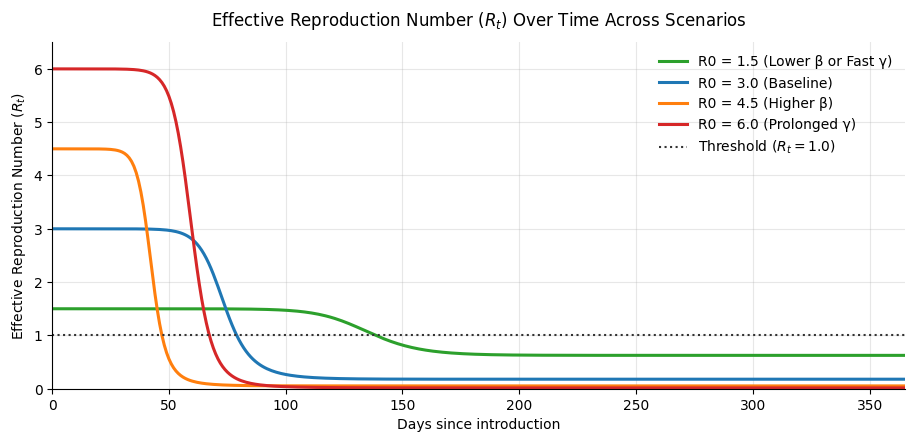

In [28]:
# Compare Rt decay across different R0 values
scenarios_r0 = {
    "R0 = 1.5 (Lower β or Fast γ)": {"beta": 0.30, "gamma": 0.20, "color": "#2CA02C"},
    "R0 = 3.0 (Baseline)": {"beta": 0.30, "gamma": 0.10, "color": "#1F77B4"},
    "R0 = 4.5 (Higher β)": {"beta": 0.45, "gamma": 0.10, "color": "#FF7F0E"},
    "R0 = 6.0 (Prolonged γ)": {"beta": 0.30, "gamma": 0.05, "color": "#D62728"},
}

fig, ax = plt.subplots(figsize=(11, 4.5))

for label, p in scenarios_r0.items():
    sol_r = solve_ivp(
        sir_model,
        t_span=(0, days),
        y0=[S0, I0, R0_initial],
        args=(p["beta"], p["gamma"], N),
        t_eval=t_eval_full,
        rtol=1e-8,
        atol=1e-8,
    )
    r0_val = p["beta"] / p["gamma"]
    rt_curve = r0_val * (sol_r.y[0] / N)
    ax.plot(sol_r.t, rt_curve, color=p["color"], linewidth=2.2, label=label)

ax.axhline(1.0, color="#333333", linestyle=":", linewidth=1.5, label="Threshold ($R_t = 1.0$)")
ax.set_title("Effective Reproduction Number ($R_t$) Over Time Across Scenarios", pad=12)
ax.set_xlabel("Days since introduction")
ax.set_ylabel("Effective Reproduction Number ($R_t$)")
ax.set_xlim(0, days)
ax.set_ylim(0, 6.5)
ax.grid(True, alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper right")

plt.show()

### 1.6.5 Multi-Scenario $R_t$ Trajectory Interpretation

Comparing how $R_t$ declines across different $R_0$ values reveals how reproduction capacity determines the speed and final outcome of an outbreak:

1. **Higher $R_0$ Drives Rapid Threshold Depletion:**

   * For the highest reproduction scenarios ($R_0 = 6.0$ and $R_0 = 4.5$), $R_t$ collapses steeply, falling below 1.0 in roughly 65 to 70 days. High initial transmission pressure burns through susceptible individuals so rapidly that the herd immunity threshold is reached early in the simulation.

   * Because of this high velocity, the momentum of active cases carries the final attack rate to nearly 100% (leaving less than 1% of the population uninfected).

2. **Lower $R_0$ Causes Prolonged, Gradual Decay:**

   * For $R_0 = 1.5$, $R_t$ starts close to the critical boundary and follows a very shallow trajectory, not crossing below 1.0 until late in the year.

   * However, because $1 - 1/R_0 = 1 - 1/1.5 \approx 33.3\%$, it requires a much smaller share of the population to reach the herd immunity threshold. Even with overshoot, the outbreak exhausts its transmission potential by Day 365, sparing roughly 42% of the population from ever contracting STC.

3. **Foundation for Spatial Heterogeneity:**

   * This homogeneous threshold behavior assumes that every individual in the United States shares the same $R_t$ at any given moment.
   
   * In reality, local contact patterns, geographic boundaries, and population sizes cause different regions to experience their own local $R_{i,t}$ trajectories. An urban county may drop below $R_t = 1$ weeks before an adjacent rural county even sees its first introduction, which leads directly to the need for spatial models.